# Readmission Risk Model Building
The model uses 'Kaggle Diabetes 130-US Hospitals (1999–2008)' dataset.

**Target:** `readmitted == "<30"` means readmitted within 30 days.

##Importing libraries

In [1]:
# If needed: %pip install -q kagglehub pandas numpy scikit-learn matplotlib joblib
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub
import joblib

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix, classification_report,
    RocCurveDisplay, PrecisionRecallDisplay)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)


##Downloading Kaggle dataset

In [2]:
dataset_path = kagglepath = kagglepath = kagglehub.dataset_download("brandao/diabetes")
print("Dataset directory:", dataset_path)
csv_files = list(Path(dataset_path).rglob("*.csv"))
for i, file in enumerate(csv_files):
    print(i, file)
if not csv_files:
    raise FileNotFoundError("No CSV found in downloaded dataset.")
CSV_PATH = str(csv_files[0])  # If multiple CSVs appear, select the main dataset explicitly.
print("Using:", CSV_PATH)
df = pd.read_csv(CSV_PATH)
print("Shape:", df.shape)
display(df.head())


100%|██████████| 4.41M/4.41M [00:00<00:00, 169MB/s]

Extracting files...
Dataset directory: /root/.cache/kagglehub/datasets/brandao/diabetes/versions/1
0 /root/.cache/kagglehub/datasets/brandao/diabetes/versions/1/diabetic_data.csv
Using: /root/.cache/kagglehub/datasets/brandao/diabetes/versions/1/diabetic_data.csv


Shape: (101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,?,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,?,?,1,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,?,?,59,0,18,0,0,0,276,250.01,255,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,?,?,11,5,13,2,0,1,648,250,V27,6,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,?,?,44,1,16,0,0,0,8,250.43,403,7,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,?,?,51,0,8,0,0,0,197,157,250,5,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


##Inspecting dataset and target

['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'payer_code', 'medical_specialty', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted']


,0
max_glu_serum,96420
A1Cresult,84748
race,0
gender,0
age,0
weight,0
admission_type_id,0
discharge_disposition_id,0
admission_source_id,0
time_in_hospital,0


Duplicates: 0


,count
readmitted,
NO,54864
>30,35545
<30,11357


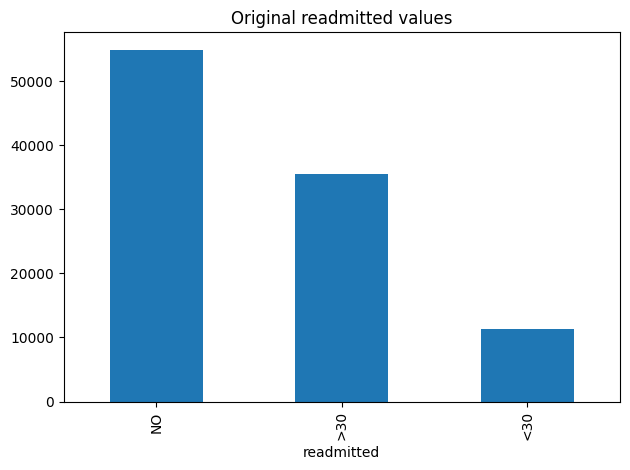

In [ ]:
print(df.columns.tolist())
display(df.isna().sum().sort_values(ascending=False).head(30))
print("Duplicates:", df.duplicated().sum())
TARGET_COL = "readmitted"
if TARGET_COL not in df:
    raise KeyError(f"Missing {TARGET_COL}; columns are {df.columns.tolist()}")
display(df[TARGET_COL].value_counts(dropna=False))
df[TARGET_COL].value_counts(dropna=False).plot(kind="bar", title="Original readmitted values")
plt.tight_layout()
plt.show()


##Feature preparation
Positive class = `<30` (readmitted within 30 days); `<30` vs `>30`/`NO` becomes binary. Patient and encounter identifiers are excluded. For a deployment-oriented model, explicitly remove any feature unavailable at the intended prediction timestamp to prevent leakage.

In [ ]:
target_raw = df[TARGET_COL].astype("string").str.strip()
valid_target = target_raw.isin(["<30", ">30", "NO"])
y = (target_raw.loc[valid_target] == "<30").astype("int8")
drop_cols = [TARGET_COL] + [c for c in ["encounter_id", "patient_nbr"] if c in df.columns]
X = df.loc[valid_target].drop(columns=drop_cols).copy()
X = X.replace(["?", "Unknown/Invalid", "Unknown", "None"], np.nan)
print("Features:", X.shape, "| Target:", y.shape, "| Positive rate:", round(y.mean(), 4))
display(X.head())


Features: (101766, 47) | Target: (101766,) | Positive rate: 0.1116


,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed
0,Caucasian,Female,[0-10),NaN,6,25,1,1,NaN,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,NaN,NaN,1,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No
1,Caucasian,Female,[10-20),NaN,1,1,7,3,NaN,NaN,59,0,18,0,0,0,276,250.01,255,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes
2,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,NaN,NaN,11,5,13,2,0,1,648,250,V27,6,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes
3,Caucasian,Male,[30-40),NaN,1,1,7,2,NaN,NaN,44,1,16,0,0,0,8,250.43,403,7,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes
4,Caucasian,Male,[40-50),NaN,1,1,7,1,NaN,NaN,51,0,8,0,0,0,197,157,250,5,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes


##Basic Exploratory Data Analysis (EDA)

In [ ]:
display(X.describe(include="all").T.head(40))
cat_cols = X.select_dtypes(include=["object", "category", "string"]).columns
display(X[cat_cols].nunique(dropna=False).sort_values(ascending=False).head(30))
for col in ["race", "gender", "age", "admission_type_id", "discharge_disposition_id"]:
    if col in X.columns:
        display(y.groupby(X[col].astype("string")).mean().rename(f"30-day readmission rate by {col}").to_frame())


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
race,99493,5,Caucasian,76099,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,101763,2,Female,54708,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,101766,10,[70-80),26068,NaN,NaN,NaN,NaN,NaN,NaN,NaN
weight,3197,9,[75-100),1336,NaN,NaN,NaN,NaN,NaN,NaN,NaN
admission_type_id,101766.0,NaN,NaN,NaN,2.024006,1.445403,1.0,1.0,1.0,3.0,8.0
discharge_disposition_id,101766.0,NaN,NaN,NaN,3.715642,5.280166,1.0,1.0,1.0,4.0,28.0
admission_source_id,101766.0,NaN,NaN,NaN,5.754437,4.064081,1.0,1.0,7.0,7.0,25.0
time_in_hospital,101766.0,NaN,NaN,NaN,4.395987,2.985108,1.0,2.0,4.0,6.0,14.0
payer_code,61510,17,MC,32439,NaN,NaN,NaN,NaN,NaN,NaN,NaN
medical_specialty,51817,72,InternalMedicine,14635,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,0
diag_3,790
diag_2,749
diag_1,717
medical_specialty,73
payer_code,18
weight,10
age,10
race,6
glyburide-metformin,4
max_glu_serum,4


,30-day readmission rate by race
race,
AfricanAmerican,0.112181
Asian,0.101404
Caucasian,0.112906
Hispanic,0.104075
Other,0.096282


,30-day readmission rate by gender
gender,
Female,0.112452
Male,0.110615


,30-day readmission rate by age
age,
[0-10),0.018634
[10-20),0.057887
[20-30),0.142426
[30-40),0.112318
[40-50),0.106040
[50-60),0.096662
[60-70),0.111284
[70-80),0.117731
[80-90),0.120835


,30-day readmission rate by admission_type_id
admission_type_id,
1,0.115225
2,0.111797
3,0.103927
4,0.100000
5,0.103448
6,0.110754
7,0.000000
8,0.084375


,30-day readmission rate by discharge_disposition_id
discharge_disposition_id,
1,0.093004
10,0.000000
11,0.000000
12,0.666667
13,0.047619
14,0.064516
15,0.444444
16,0.000000
17,0.000000


##Train / validation / test split
70% train, 15% validation, 15% test

In [ ]:
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.15, random_state=RANDOM_STATE, stratify=y)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_full, y_train_full, test_size=0.15/0.85,
    random_state=RANDOM_STATE, stratify=y_train_full)
for name, xx, yy in [("Train", X_train, y_train), ("Validation", X_valid, y_valid), ("Test", X_test, y_test)]:
    print(name, xx.shape, "positive rate:", round(yy.mean(), 4))


Train (71236, 47) positive rate: 0.1116
Validation (15265, 47) positive rate: 0.1116
Test (15265, 47) positive rate: 0.1116


##Preprocessing pipeline

In [ ]:
numeric_features = X_train.select_dtypes(include=["number", "bool"]).columns.tolist()
categorical_features = [c for c in X_train.columns if c not in numeric_features]
numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=10))
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipe, numeric_features),
    ("cat", categorical_pipe, categorical_features)
])
print("Numeric:", len(numeric_features), "Categorical:", len(categorical_features))


Numeric: 11 Categorical: 36


##Evaluation helper

In [ ]:
def evaluate_model(model, X_eval, y_eval, label, threshold=0.5):
    probabilities = model.predict_proba(X_eval)[:, 1] if hasattr(model, "predict_proba") else None
    predictions = (probabilities >= threshold).astype(int) if probabilities is not None else model.predict(X_eval)
    metrics = {
        "model": label,
        "accuracy": accuracy_score(y_eval, predictions),
        "precision": precision_score(y_eval, predictions, zero_division=0),
        "recall": recall_score(y_eval, predictions, zero_division=0),
        "f1": f1_score(y_eval, predictions, zero_division=0)
    }
    if probabilities is not None:
        metrics["roc_auc"] = roc_auc_score(y_eval, probabilities)
        metrics["average_precision"] = average_precision_score(y_eval, probabilities)
    print(label)
    print(classification_report(y_eval, predictions, target_names=["Not <30-day", "<30-day"], zero_division=0))
    print("Confusion matrix:\n", confusion_matrix(y_eval, predictions))
    return metrics, predictions, probabilities


##Baseline and candidate models

In [ ]:
baseline = DummyClassifier(strategy="prior").fit(X_train, y_train)
baseline_metrics, _, _ = evaluate_model(baseline, X_valid, y_valid, "Dummy prior baseline")

models = {
    "Logistic Regression": Pipeline([
        ("preprocess", preprocessor),
        ("model", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE))
    ]),
    "Random Forest": Pipeline([
        ("preprocess", preprocessor),
        ("model", RandomForestClassifier(n_estimators=300, min_samples_leaf=2,
            class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1))
    ])
}
fitted = {}
results = []
for name, model in models.items():
    print("Training", name)
    model.fit(X_train, y_train)
    metrics, _, _ = evaluate_model(model, X_valid, y_valid, name)
    results.append(metrics)
    fitted[name] = model
results_df = pd.DataFrame(results).sort_values("average_precision", ascending=False)
display(results_df)


Dummy prior baseline
              precision    recall  f1-score   support

 Not <30-day       0.89      1.00      0.94     13562
     <30-day       0.00      0.00      0.00      1703

    accuracy                           0.89     15265
   macro avg       0.44      0.50      0.47     15265
weighted avg       0.79      0.89      0.84     15265

Confusion matrix:
 [[13562     0]
 [ 1703     0]]
Training Logistic Regression
Logistic Regression
              precision    recall  f1-score   support

 Not <30-day       0.92      0.65      0.76     13562
     <30-day       0.16      0.52      0.24      1703

    accuracy                           0.64     15265
   macro avg       0.54      0.59      0.50     15265
weighted avg       0.83      0.64      0.70     15265

Confusion matrix:
 [[8834 4728]
 [ 810  893]]
Training Random Forest
Random Forest
              precision    recall  f1-score   support

 Not <30-day       0.90      0.97      0.93     13562
     <30-day       0.31      0.12 

,model,accuracy,precision,recall,f1,roc_auc,average_precision
1,Random Forest,0.872781,0.314152,0.118614,0.172208,0.655090,0.203289
0,Logistic Regression,0.637209,0.158869,0.524369,0.243856,0.631129,0.189678


##Model selection and tuning (optional)
Select by validation average precision (PR-AUC), useful for an imbalanced target. Tune only using training data and cross-validation.

In [ ]:
best_name = results_df.iloc[0]["model"]
best_candidate = fitted[best_name]
print("Selected:", best_name)

if best_name == "Random Forest":
    params = {
        "model__n_estimators": [200, 300, 500],
        "model__max_depth": [None, 10, 20, 30],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 5],
        "model__max_features": ["sqrt", 0.5, 0.8]
    }
    search = RandomizedSearchCV(best_candidate, params, n_iter=12,
        scoring="average_precision", cv=3, random_state=RANDOM_STATE, n_jobs=-1, verbose=1)
    search.fit(X_train, y_train)
    final_model = search.best_estimator_
    print("Best CV average precision:", search.best_score_)
    print("Best params:", search.best_params_)
else:
    final_model = best_candidate
    print("No extra tuning applied to Logistic Regression in this notebook.")


Selected: Random Forest
Fitting 3 folds for each of 12 candidates, totalling 36 fits


## 11. Select decision threshold on validation set
A 0.5 threshold is not necessarily suitable. This selects the threshold with best validation F1, then locks it before test evaluation. For real clinical use, threshold choice must reflect workflow and false-negative/false-positive costs.

In [ ]:
valid_prob = final_model.predict_proba(X_valid)[:, 1]
threshold_rows = []
for t in np.arange(0.10, 0.91, 0.05):
    pred = (valid_prob >= t).astype(int)
    threshold_rows.append({"threshold": round(float(t), 2),
        "precision": precision_score(y_valid, pred, zero_division=0),
        "recall": recall_score(y_valid, pred, zero_division=0),
        "f1": f1_score(y_valid, pred, zero_division=0)})
threshold_df = pd.DataFrame(threshold_rows)
display(threshold_df)
best_threshold = float(threshold_df.loc[threshold_df["f1"].idxmax(), "threshold"])
print("Locked threshold:", best_threshold)


## 12. Final test evaluation
Run this after model/threshold selection. Do not tune based on test results.

In [ ]:
test_metrics, test_predictions, test_probabilities = evaluate_model(
    final_model, X_test, y_test, f"Final test — {best_name}", threshold=best_threshold)
display(pd.DataFrame([test_metrics]))


In [ ]:
RocCurveDisplay.from_predictions(y_test, test_probabilities)
plt.title("ROC curve — held-out test set")
plt.tight_layout()
plt.show()
PrecisionRecallDisplay.from_predictions(y_test, test_probabilities)
plt.title("Precision-Recall curve — held-out test set")
plt.tight_layout()
plt.show()


## 13. Save model and metadata

In [ ]:
artifact_dir = Path("readmission_model_artifacts")
artifact_dir.mkdir(exist_ok=True)
model_path = artifact_dir / "readmission_model.joblib"
metadata_path = artifact_dir / "metadata.joblib"
joblib.dump(final_model, model_path)
metadata = {
    "target_definition": 'readmitted == "<30"',
    "positive_class": 1,
    "selected_model": best_name,
    "decision_threshold": best_threshold,
    "random_state": RANDOM_STATE,
    "test_metrics": test_metrics,
    "feature_columns": X.columns.tolist()
}
joblib.dump(metadata, metadata_path)
print("Saved:", model_path.resolve())
print("Saved:", metadata_path.resolve())


## 14. Load and test one prediction

In [ ]:
loaded_model = joblib.load(model_path)
sample = X_test.iloc[[0]]
probability = loaded_model.predict_proba(sample)[:, 1][0]
predicted_class = int(probability >= best_threshold)
print("Predicted probability of <30-day readmission:", round(float(probability), 4))
print("Predicted class:", predicted_class)


## 15. Limitations / checklist
- Confirm target and prediction timestamp.
- Investigate leakage from features unavailable at prediction time.
- Report class imbalance, baseline, test metrics, and confusion matrix.
- This is not clinically validated and must not be used for patient care.
- Deployment (FastAPI, Docker, managed runtime, monitoring, CI/CD, rollback, load/SLO tests) is deliberately out of scope for this notebook.